<a href="https://colab.research.google.com/github/Pradeep-Kumar-Panga/DecodingComplexities/blob/main/GradientDescent.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div style="background:#0d0d0d; padding:32px 40px; border-radius:12px; border-left:5px solid #7B61FF;">
<h1 style="color:#FFFFFF; font-family:monospace; margin:0 0 8px 0; font-size:26px;">
  📉 Gradient Descent from Scratch
</h1>
<p style="color:#9E9E9E; font-size:14px; margin:0;">
  Decoding Complexities · companion notebook
</p>
<p style="color:#9E9E9E; font-size:13px; margin:8px 0 0 0;">
  pradeeppanga.com · @DecodingComplexities
</p>
</div>

---

### What this notebook covers

| Section | Concept |
|---|---|
| 1 | The update rule — derived from first principles |
| 2 | Learning rate sensitivity — too small, too large, just right |
| 3 | Implementing vanilla GD from scratch — no libraries |
| 4 | Visualising descent on a quadratic bowl (convex) |
| 5 | Where vanilla GD breaks — the Rosenbrock surface |
| 6 | Visualising failure modes — slow convergence, oscillation |
| 7 | What this tells us about optimisers |

> **No PyTorch. No TensorFlow. No autograd.**
> Every gradient is computed by hand or with numpy only.
> That is the point.

---
## Section 1 — The Update Rule: Derived from First Principles

The question is simple: given a loss function $L(\theta)$, how do we find the $\theta$ that minimises it?

### The core idea

If you are standing on a hilly surface and want to reach the lowest point, you look around and take a step in the direction that goes downhill the fastest.

The gradient $\nabla L(\theta)$ points in the direction of **steepest ascent**.  
So we move in the **opposite** direction — steepest descent.

### The update rule

$$\theta_{t+1} = \theta_t - \eta \nabla L(\theta_t)$$

Where:
- $\theta_t$ — current parameters at step $t$
- $\eta$ — learning rate (step size)
- $\nabla L(\theta_t)$ — gradient of loss with respect to parameters

### Why subtract?

Because the gradient points uphill. Subtracting it moves us downhill.  
The learning rate $\eta$ controls how far we step in that direction.

### A single variable example first

Let $L(\theta) = \theta^2$. Then $\nabla L(\theta) = 2\theta$.

Update rule becomes: $\theta_{t+1} = \theta_t - \eta \cdot 2\theta_t$

The minimum is at $\theta = 0$. Let's verify this works.

In [1]:
# Setup
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.mplot3d import Axes3D
from matplotlib import cm
import warnings
warnings.filterwarnings('ignore')

# Dark theme — matches on-screen recording
plt.rcParams.update({
    'figure.facecolor':  '#0d0d0d',
    'axes.facecolor':    '#1a1a1a',
    'axes.edgecolor':    '#444444',
    'axes.labelcolor':   '#cccccc',
    'text.color':        '#cccccc',
    'xtick.color':       '#888888',
    'ytick.color':       '#888888',
    'grid.color':        '#2a2a2a',
    'grid.linestyle':    '--',
    'lines.linewidth':   2.0,
    'font.family':       'monospace',
    'legend.facecolor':  '#1a1a1a',
    'legend.edgecolor':  '#444444',
})

PURPLE = '#7B61FF'
TEAL   = '#00C9A7'
CORAL  = '#FF6B6B'
AMBER  = '#FFB347'
WHITE  = '#EEEEEE'
MUTED  = '#888888'
GREEN  = '#69DB7C'

print("Setup complete.")

Setup complete.


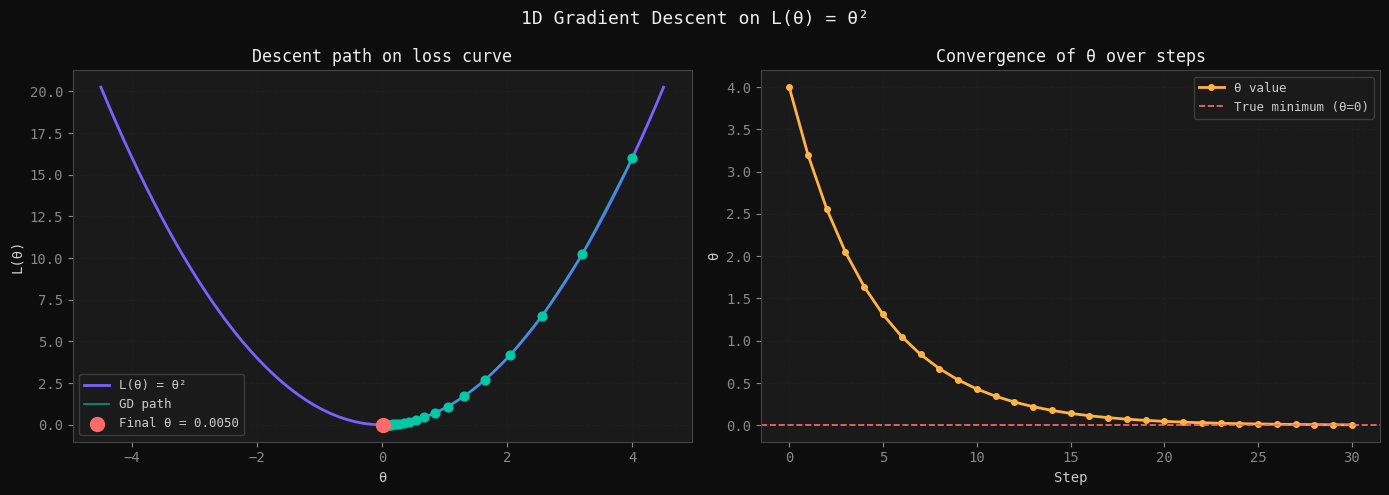

Starting θ:  4.0
Final θ:     0.00495176
True minimum: 0.0

Update rule applied 30 times: θ = θ - 0.1 × 2θ


In [2]:
# 1D gradient descent on L(θ) = θ²

def loss_1d(theta):
    return theta ** 2

def grad_1d(theta):
    return 2 * theta   # analytic gradient — derived by hand

def gradient_descent_1d(theta_init, lr, n_steps):
    theta = theta_init
    history = [theta]
    for _ in range(n_steps):
        grad = grad_1d(theta)
        theta = theta - lr * grad   # THE update rule
        history.append(theta)
    return np.array(history)

# Run with a sensible learning rate
theta_init = 4.0
lr         = 0.1
n_steps    = 30
history    = gradient_descent_1d(theta_init, lr, n_steps)

# Plot
theta_range = np.linspace(-4.5, 4.5, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("1D Gradient Descent on L(θ) = θ²", color=WHITE, fontsize=13)

# Left: loss curve with descent path
ax1.plot(theta_range, loss_1d(theta_range), color=PURPLE, lw=2, label="L(θ) = θ²")
ax1.scatter(history, loss_1d(history), color=TEAL, s=40, zorder=5)
ax1.plot(history, loss_1d(history), color=TEAL, lw=1.2, alpha=0.7, label="GD path")
ax1.scatter([history[-1]], [loss_1d(history[-1])], color=CORAL, s=100,
            zorder=6, label=f"Final θ = {history[-1]:.4f}")
ax1.set_xlabel("θ"); ax1.set_ylabel("L(θ)")
ax1.set_title("Descent path on loss curve", color=WHITE)
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.3)

# Right: θ convergence over steps
ax2.plot(range(len(history)), history, color=AMBER, lw=2, marker='o',
         markersize=4, label="θ value")
ax2.axhline(0, color=CORAL, lw=1.2, linestyle='--', label="True minimum (θ=0)")
ax2.set_xlabel("Step"); ax2.set_ylabel("θ")
ax2.set_title("Convergence of θ over steps", color=WHITE)
ax2.legend(fontsize=9); ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('gd_1d.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

print(f"Starting θ:  {theta_init}")
print(f"Final θ:     {history[-1]:.8f}")
print(f"True minimum: 0.0")
print(f"\nUpdate rule applied {n_steps} times: θ = θ - {lr} × 2θ")

---
## Section 2 — Learning Rate Sensitivity

The learning rate $\eta$ is not just a hyperparameter.  
It is the mechanism by which the gradient's direction gets translated into an actual update.

Three regimes:

| Learning rate | Behaviour |
|---|---|
| Too small | Takes tiny steps — converges, but extremely slowly |
| Just right | Converges efficiently |
| Too large | Overshoots — diverges or oscillates |

We will demonstrate all three on the same loss function.

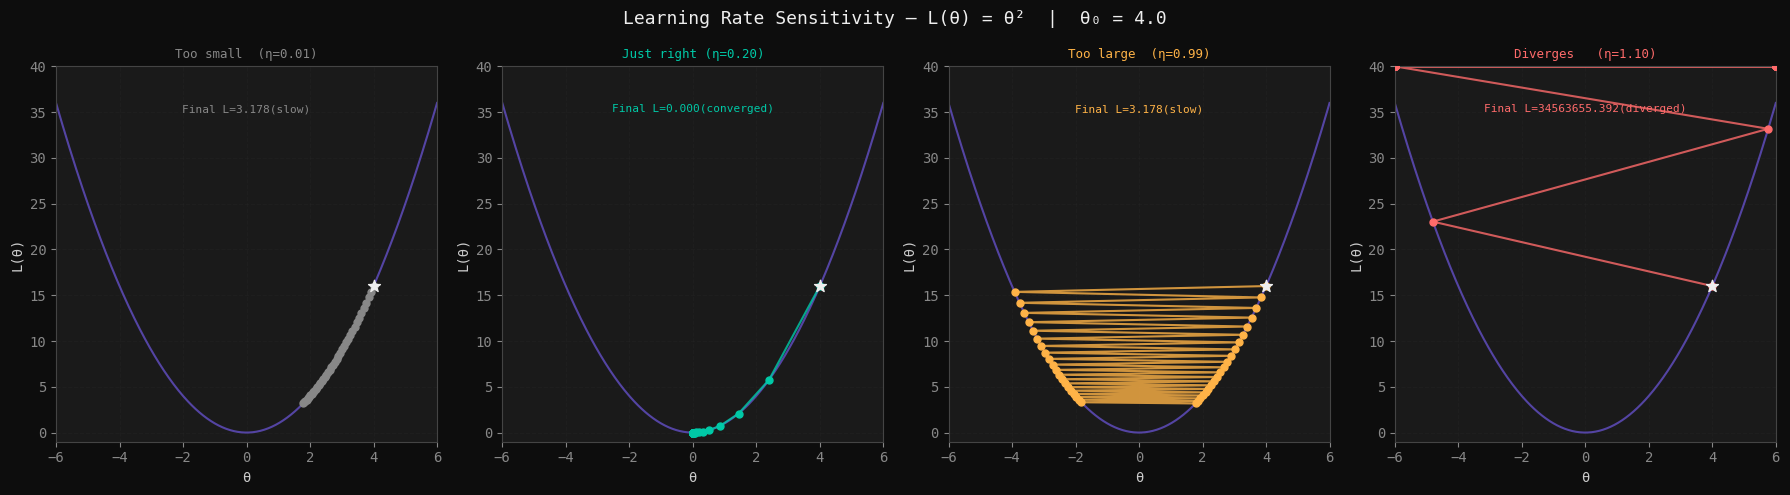

In [3]:
# Learning rate sensitivity on L(θ) = θ²

learning_rates = {
    'Too small  (η=0.01)': 0.01,
    'Just right (η=0.20)': 0.20,
    'Too large  (η=0.99)': 0.99,
    'Diverges   (η=1.10)': 1.10,
}
colors = [MUTED, TEAL, AMBER, CORAL]
n_steps = 40

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle("Learning Rate Sensitivity — L(θ) = θ²  |  θ₀ = 4.0",
             color=WHITE, fontsize=13)

theta_range = np.linspace(-6, 6, 400)

for ax, (label, lr), color in zip(axes, learning_rates.items(), colors):
    history = gradient_descent_1d(theta_init=4.0, lr=lr, n_steps=n_steps)

    ax.plot(theta_range, loss_1d(theta_range), color=PURPLE, lw=1.5, alpha=0.6)

    # Clip for display — diverging runs go to infinity
    history_clipped = np.clip(history, -6, 6)
    loss_clipped    = np.clip(loss_1d(history), 0, 40)

    ax.scatter(history_clipped, loss_clipped, color=color, s=25, zorder=5)
    ax.plot(history_clipped, loss_clipped, color=color, lw=1.5, alpha=0.8)
    ax.scatter([history_clipped[0]], [loss_clipped[0]], color=WHITE, s=80,
               zorder=6, marker='*')

    ax.set_title(label, color=color, fontsize=9)
    ax.set_xlabel("θ"); ax.set_ylabel("L(θ)")
    ax.set_xlim(-6, 6); ax.set_ylim(-1, 40)
    ax.grid(True, alpha=0.3)

    final_loss = loss_1d(history[-1])
    status = "converged" if final_loss < 0.01 else ("diverged" if final_loss > 100 else "slow")
    ax.text(0, 35, f"Final L={final_loss:.3f}({status})",
            color=color, fontsize=8, ha='center')

plt.tight_layout()
plt.savefig('lr_sensitivity.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

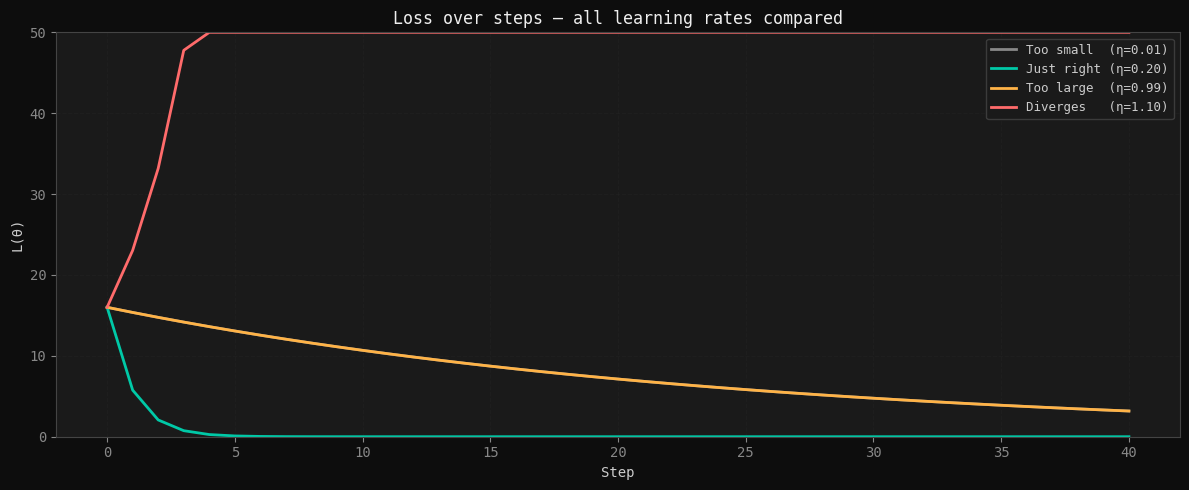

Key observation:
  η too small → loss decreases but very slowly
  η just right → loss drops rapidly and settles
  η too large → loss oscillates or explodes

The gradient gives direction. The learning rate gives distance.
Get one wrong and the other is useless.


In [4]:
# Convergence curves for all learning rates side by side

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_title("Loss over steps — all learning rates compared", color=WHITE, fontsize=12)

for (label, lr), color in zip(learning_rates.items(), colors):
    history = gradient_descent_1d(theta_init=4.0, lr=lr, n_steps=40)
    losses  = np.clip(loss_1d(history), 0, 50)
    ax.plot(losses, color=color, lw=2, label=label)

ax.set_xlabel("Step"); ax.set_ylabel("L(θ)")
ax.set_ylim(0, 50); ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('lr_convergence.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

print("Key observation:")
print("  η too small → loss decreases but very slowly")
print("  η just right → loss drops rapidly and settles")
print("  η too large → loss oscillates or explodes")
print()
print("The gradient gives direction. The learning rate gives distance.")
print("Get one wrong and the other is useless.")

---
## Section 3 — Implementing Vanilla GD from Scratch

Now we move to two dimensions — a model with two parameters $\theta_1$ and $\theta_2$.

This is the minimum realistic case: real models have millions of parameters,  
but the geometry is identical. Two dimensions lets us see everything.

### Loss function

$$L(\theta_1, \theta_2) = \theta_1^2 + 5\theta_2^2$$

This is an **elliptical bowl** — convex, one global minimum at $(0, 0)$.  
The $5\theta_2^2$ term makes it asymmetric — steeper in one direction than the other.  
This asymmetry will expose learning rate sensitivity in 2D.

### Analytic gradients

$$\frac{\partial L}{\partial \theta_1} = 2\theta_1 \qquad \frac{\partial L}{\partial \theta_2} = 10\theta_2$$

### Update rule (vector form)

$$\begin{pmatrix} \theta_1 \\ \theta_2 \end{pmatrix}_{t+1} = \begin{pmatrix} \theta_1 \\ \theta_2 \end{pmatrix}_t - \eta \begin{pmatrix} 2\theta_1 \\ 10\theta_2 \end{pmatrix}_t$$

In [5]:
# 2D loss function and analytic gradients

def loss_bowl(theta):
    """Elliptical bowl: L(θ₁, θ₂) = θ₁² + 5θ₂²"""
    return theta[0]**2 + 5 * theta[1]**2

def grad_bowl(theta):
    """Analytic gradient of the bowl."""
    return np.array([2 * theta[0],
                     10 * theta[1]])

def gradient_descent_2d(loss_fn, grad_fn, theta_init, lr, n_steps):
    """
    Vanilla gradient descent in 2D.

    Parameters
    ----------
    loss_fn    : callable — L(theta)
    grad_fn    : callable — ∇L(theta)
    theta_init : np.ndarray shape (2,)
    lr         : float — learning rate
    n_steps    : int

    Returns
    -------
    history_theta : (n_steps+1, 2) — parameter trajectory
    history_loss  : (n_steps+1,)   — loss at each step
    """
    theta = theta_init.copy().astype(float)
    history_theta = [theta.copy()]
    history_loss  = [loss_fn(theta)]

    for step in range(n_steps):
        grad  = grad_fn(theta)          # compute gradient
        theta = theta - lr * grad       # apply update rule
        history_theta.append(theta.copy())
        history_loss.append(loss_fn(theta))

    return np.array(history_theta), np.array(history_loss)

# Quick test
theta_init = np.array([4.0, 2.0])
path, losses = gradient_descent_2d(loss_bowl, grad_bowl, theta_init, lr=0.09, n_steps=50)

print("Vanilla GD on elliptical bowl")
print(f"  Start:  θ = {theta_init},  L = {loss_bowl(theta_init):.4f}")
print(f"  End:    θ = {path[-1]},  L = {losses[-1]:.8f}")
print(f"  Steps:  50")
print(f"  Minimum: θ = [0, 0],  L = 0.0")

Vanilla GD on elliptical bowl
  Start:  θ = [4. 2.],  L = 36.0000
  End:    θ = [1.9622422e-04 2.0000000e-50],  L = 0.00000004
  Steps:  50
  Minimum: θ = [0, 0],  L = 0.0


---
## Section 4 — Visualising Descent on the Quadratic Bowl

Three views:
1. **Contour plot** — the path from above, showing how GD navigates the ellipse
2. **3D surface** — the actual loss landscape with the descent path on it
3. **Loss over steps** — convergence curve

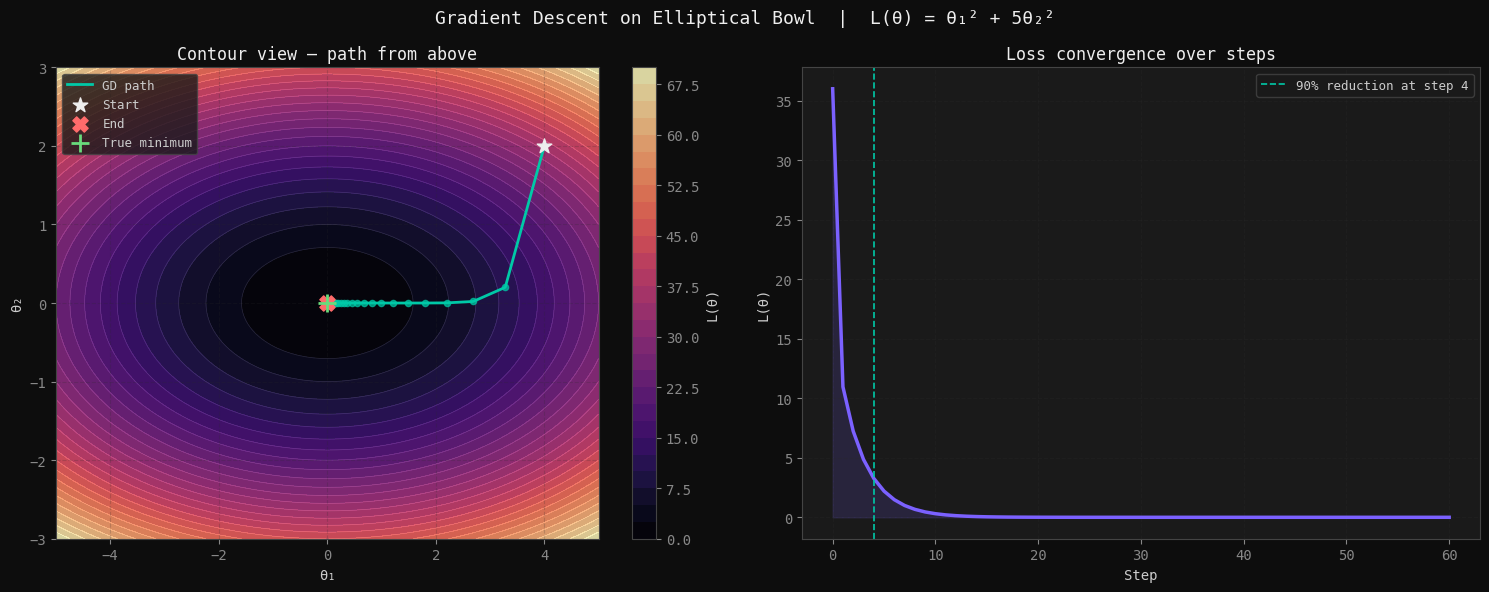

In [6]:
# Contour plot: GD path from above

theta1_range = np.linspace(-5, 5, 300)
theta2_range = np.linspace(-3, 3, 300)
T1, T2 = np.meshgrid(theta1_range, theta2_range)
Z_bowl  = T1**2 + 5 * T2**2

theta_init = np.array([4.0, 2.0])
lr         = 0.09
n_steps    = 60
path, losses = gradient_descent_2d(loss_bowl, grad_bowl, theta_init, lr, n_steps)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
fig.suptitle("Gradient Descent on Elliptical Bowl  |  L(θ) = θ₁² + 5θ₂²",
             color=WHITE, fontsize=13)

# Left: contour
ax = axes[0]
contour = ax.contourf(T1, T2, Z_bowl, levels=30, cmap='magma', alpha=0.85)
ax.contour(T1, T2, Z_bowl, levels=30, colors='white', alpha=0.15, linewidths=0.5)
plt.colorbar(contour, ax=ax, label='L(θ)')

# Plot path
ax.plot(path[:, 0], path[:, 1], color=TEAL, lw=2, zorder=5, label='GD path')
ax.scatter(path[:, 0], path[:, 1], color=TEAL, s=20, zorder=6, alpha=0.7)
ax.scatter(*theta_init, color=WHITE, s=120, zorder=7, marker='*', label='Start')
ax.scatter(*path[-1], color=CORAL, s=120, zorder=7, marker='X', label='End')
ax.scatter(0, 0, color=GREEN, s=150, zorder=8, marker='+', label='True minimum')

ax.set_xlabel("θ₁"); ax.set_ylabel("θ₂")
ax.set_title("Contour view — path from above", color=WHITE)
ax.legend(fontsize=9); ax.grid(True, alpha=0.2)

# Right: loss convergence
ax2 = axes[1]
ax2.plot(losses, color=PURPLE, lw=2.5)
ax2.fill_between(range(len(losses)), losses, alpha=0.15, color=PURPLE)
ax2.set_xlabel("Step"); ax2.set_ylabel("L(θ)")
ax2.set_title("Loss convergence over steps", color=WHITE)
ax2.grid(True, alpha=0.3)

# Annotate 90% reduction point
target = losses[0] * 0.1
idx_90 = np.argmax(losses < target)
if idx_90 > 0:
    ax2.axvline(idx_90, color=TEAL, lw=1.2, linestyle='--',
                label=f"90% reduction at step {idx_90}")
    ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig('bowl_contour.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

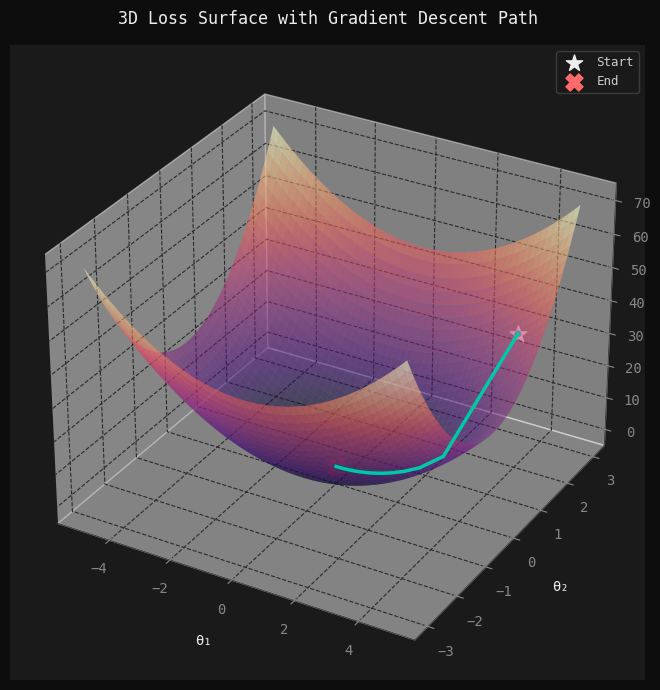

In [7]:
# 3D surface with descent path

fig = plt.figure(figsize=(13, 7))
fig.patch.set_facecolor('#0d0d0d')
ax = fig.add_subplot(111, projection='3d')
ax.set_facecolor('#1a1a1a')

# Surface
surf = ax.plot_surface(T1, T2, Z_bowl, cmap='magma', alpha=0.55,
                        linewidth=0, antialiased=True)

# Descent path — elevate slightly above surface for visibility
path_z = losses + 0.3
ax.plot(path[:, 0], path[:, 1], path_z, color=TEAL, lw=2.5, zorder=10)
ax.scatter(path[:, 0], path[:, 1], path_z, color=TEAL, s=15, zorder=11, alpha=0.7)
ax.scatter(*theta_init, losses[0] + 0.3, color=WHITE, s=150,
           zorder=12, marker='*', label='Start')
ax.scatter(*path[-1], losses[-1] + 0.3, color=CORAL, s=150,
           zorder=12, marker='X', label='End')

ax.set_xlabel('θ₁', color=WHITE, labelpad=10)
ax.set_ylabel('θ₂', color=WHITE, labelpad=10)
ax.set_zlabel('L(θ)', color=WHITE, labelpad=10)
ax.set_title("3D Loss Surface with Gradient Descent Path",
             color=WHITE, fontsize=12, pad=15)
ax.tick_params(colors=MUTED)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig('bowl_3d.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

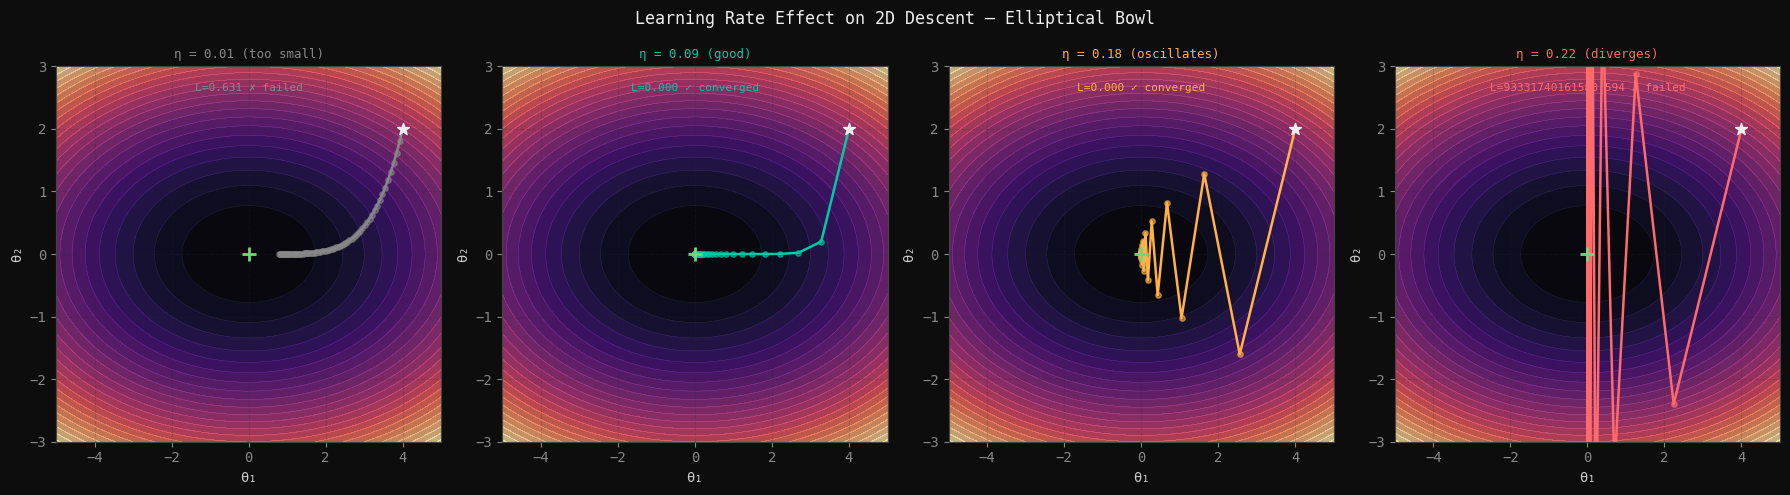

In [8]:
# Effect of learning rate on 2D descent path

lr_configs = [
    ('η = 0.01 (too small)', 0.01, MUTED),
    ('η = 0.09 (good)',      0.09, TEAL),
    ('η = 0.18 (oscillates)',0.18, AMBER),
    ('η = 0.22 (diverges)',  0.22, CORAL),
]

fig, axes = plt.subplots(1, 4, figsize=(18, 5))
fig.suptitle("Learning Rate Effect on 2D Descent — Elliptical Bowl",
             color=WHITE, fontsize=12)

for ax, (label, lr, color) in zip(axes, lr_configs):
    path_lr, losses_lr = gradient_descent_2d(
        loss_bowl, grad_bowl, np.array([4.0, 2.0]), lr, n_steps=80)

    ax.contourf(T1, T2, Z_bowl, levels=25, cmap='magma', alpha=0.75)
    ax.contour(T1, T2, Z_bowl, levels=25, colors='white', alpha=0.1, linewidths=0.4)

    path_clipped = np.clip(path_lr, -5, 5)
    ax.plot(path_clipped[:, 0], path_clipped[:, 1], color=color, lw=1.8)
    ax.scatter(path_clipped[:, 0], path_clipped[:, 1], color=color, s=15, alpha=0.6)
    ax.scatter(*np.array([4.0, 2.0]), color=WHITE, s=80, marker='*', zorder=5)
    ax.scatter(0, 0, color=GREEN, s=100, marker='+', zorder=5)

    ax.set_xlim(-5, 5); ax.set_ylim(-3, 3)
    ax.set_title(label, color=color, fontsize=9)
    ax.set_xlabel("θ₁"); ax.set_ylabel("θ₂")
    ax.grid(True, alpha=0.2)

    final_loss = losses_lr[-1]
    status = "✓ converged" if final_loss < 0.1 else "✗ failed"
    ax.text(0, 2.6, f"L={final_loss:.3f} {status}",
            color=color, fontsize=8, ha='center')

plt.tight_layout()
plt.savefig('bowl_lr_2d.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

---
## Section 5 — Where Vanilla GD Breaks: The Rosenbrock Surface

The elliptical bowl is convex. Gradient descent is **guaranteed** to find  
the global minimum on convex surfaces, given a small enough learning rate.

Real loss surfaces are not convex.

### The Rosenbrock function

$$L(\theta_1, \theta_2) = (1 - \theta_1)^2 + 100(\theta_2 - \theta_1^2)^2$$

Properties that make it hard:
- **One global minimum** at $(1, 1)$ where $L = 0$
- **A long, narrow, curved valley** — the gradient along the valley floor is almost zero
- **Steep walls** on either side of the valley
- Gradient descent finds the valley quickly, then **crawls** along it

This is a canonical example of why vanilla GD fails in practice and why  
momentum-based optimisers were developed. We are not implementing those here —  
but we will see exactly what the problem looks like.

### Analytic gradients

$$\frac{\partial L}{\partial \theta_1} = -2(1 - \theta_1) - 400\theta_1(\theta_2 - \theta_1^2)$$

$$\frac{\partial L}{\partial \theta_2} = 200(\theta_2 - \theta_1^2)$$

In [9]:
# Rosenbrock function and gradients

def loss_rosenbrock(theta):
    """
    Rosenbrock function.
    Global minimum at θ = (1, 1) where L = 0.
    """
    t1, t2 = theta[0], theta[1]
    return (1 - t1)**2 + 100 * (t2 - t1**2)**2

def grad_rosenbrock(theta):
    """Analytic gradient of the Rosenbrock function."""
    t1, t2 = theta[0], theta[1]
    dl_dt1 = -2 * (1 - t1) - 400 * t1 * (t2 - t1**2)
    dl_dt2 = 200 * (t2 - t1**2)
    return np.array([dl_dt1, dl_dt2])

# Verify: gradient should be zero at the minimum
minimum = np.array([1.0, 1.0])
print(f"L at minimum (1,1):          {loss_rosenbrock(minimum):.6f}  (should be 0)")
print(f"Gradient at minimum (1,1):   {grad_rosenbrock(minimum)}  (should be [0,0])")
print()

# Starting point
theta_init_rb = np.array([-1.0, 1.0])
print(f"Starting point:  θ = {theta_init_rb}")
print(f"Starting loss:   L = {loss_rosenbrock(theta_init_rb):.2f}")

L at minimum (1,1):          0.000000  (should be 0)
Gradient at minimum (1,1):   [-0.  0.]  (should be [0,0])

Starting point:  θ = [-1.  1.]
Starting loss:   L = 4.00


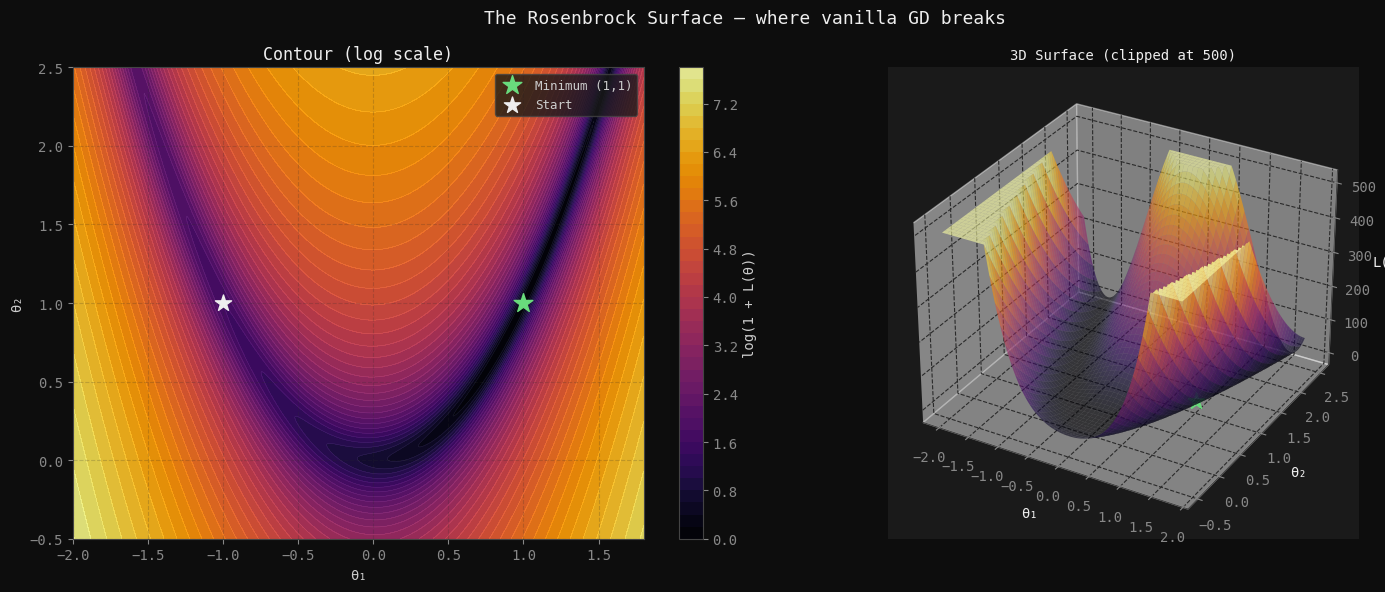

Notice: the valley floor is nearly flat.
The gradient along the valley is tiny — gradient descent crawls.
The walls are steep — a large learning rate causes oscillation.
This is the fundamental tension vanilla GD cannot resolve.


In [10]:
# Visualise the Rosenbrock surface

t1_range = np.linspace(-2.0, 1.8, 400)
t2_range = np.linspace(-0.5, 2.5, 400)
T1_rb, T2_rb = np.meshgrid(t1_range, t2_range)
Z_rb = (1 - T1_rb)**2 + 100 * (T2_rb - T1_rb**2)**2

fig = plt.figure(figsize=(15, 6))
fig.patch.set_facecolor('#0d0d0d')
fig.suptitle("The Rosenbrock Surface — where vanilla GD breaks",
             color=WHITE, fontsize=13)

# Left: contour (log scale for visibility)
ax1 = fig.add_subplot(121)
Z_log = np.log1p(Z_rb)
contour = ax1.contourf(T1_rb, T2_rb, Z_log, levels=40, cmap='inferno', alpha=0.9)
ax1.contour(T1_rb, T2_rb, Z_log, levels=40, colors='white', alpha=0.1, linewidths=0.4)
plt.colorbar(contour, ax=ax1, label='log(1 + L(θ))')
ax1.scatter(1, 1, color=GREEN, s=200, marker='*', zorder=6, label='Minimum (1,1)')
ax1.scatter(*theta_init_rb, color=WHITE, s=150, marker='*', zorder=6, label='Start')
ax1.set_xlabel("θ₁"); ax1.set_ylabel("θ₂")
ax1.set_title("Contour (log scale)", color=WHITE)
ax1.legend(fontsize=9); ax1.grid(True, alpha=0.2)

# Right: 3D surface
ax2 = fig.add_subplot(122, projection='3d')
ax2.set_facecolor('#1a1a1a')
Z_rb_clipped = np.clip(Z_rb, 0, 500)
surf = ax2.plot_surface(T1_rb, T2_rb, Z_rb_clipped,
                         cmap='inferno', alpha=0.6,
                         linewidth=0, antialiased=True)
ax2.scatter([1], [1], [0], color=GREEN, s=150, marker='*', zorder=6)
ax2.set_xlabel('θ₁', color=WHITE); ax2.set_ylabel('θ₂', color=WHITE)
ax2.set_zlabel('L(θ)', color=WHITE)
ax2.set_title("3D Surface (clipped at 500)", color=WHITE, fontsize=10)
ax2.tick_params(colors=MUTED)

plt.tight_layout()
plt.savefig('rosenbrock_surface.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

print("Notice: the valley floor is nearly flat.")
print("The gradient along the valley is tiny — gradient descent crawls.")
print("The walls are steep — a large learning rate causes oscillation.")
print("This is the fundamental tension vanilla GD cannot resolve.")

---
## Section 6 — Visualising Failure Modes on the Rosenbrock

We run vanilla GD with different learning rates and observe exactly where it fails.

The three failure modes you will see:

| Mode | Cause | Visual signature |
|---|---|---|
| Crawling | η too small — tiny steps along flat valley | Path hugs the valley but barely moves |
| Oscillation | η too large — overshoots the steep walls | Path zigzags across the valley |
| Divergence | η far too large — explodes | Path leaves the surface entirely |

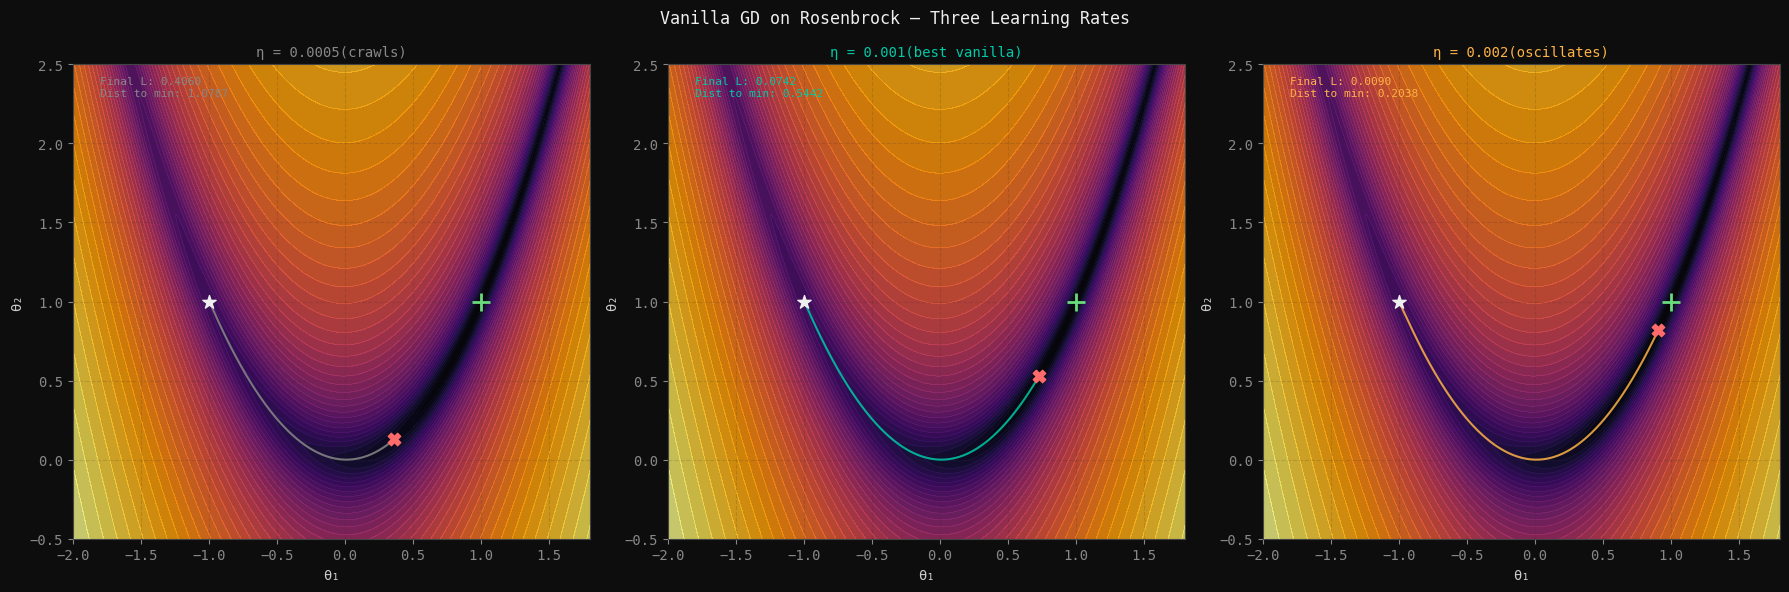

In [11]:
# GD on Rosenbrock — three learning rates

rb_configs = [
    ('η = 0.0005(crawls)',     0.0005, 2000, MUTED),
    ('η = 0.001(best vanilla)',0.001,  2000, TEAL),
    ('η = 0.002(oscillates)', 0.002,  2000, AMBER),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Vanilla GD on Rosenbrock — Three Learning Rates",
             color=WHITE, fontsize=12)

Z_log = np.log1p(Z_rb)

for ax, (label, lr, steps, color) in zip(axes, rb_configs):
    path_rb, losses_rb = gradient_descent_2d(
        loss_rosenbrock, grad_rosenbrock,
        np.array([-1.0, 1.0]), lr, n_steps=steps)

    # Clip path for display
    p = np.clip(path_rb, -2.0, 1.8)
    # Only plot every Nth point to avoid overplotting on long runs
    stride = max(1, len(p) // 300)

    ax.contourf(T1_rb, T2_rb, Z_log, levels=40, cmap='inferno', alpha=0.8)
    ax.contour(T1_rb, T2_rb, Z_log, levels=40, colors='white',
               alpha=0.08, linewidths=0.3)

    ax.plot(p[::stride, 0], p[::stride, 1], color=color, lw=1.5, alpha=0.85)
    ax.scatter(p[0, 0], p[0, 1], color=WHITE, s=100, marker='*', zorder=6)
    ax.scatter(1, 1, color=GREEN, s=150, marker='+', zorder=6, linewidths=2)
    ax.scatter(p[-1, 0], p[-1, 1], color=CORAL, s=80, marker='X', zorder=6)

    ax.set_xlim(-2.0, 1.8); ax.set_ylim(-0.5, 2.5)
    ax.set_xlabel("θ₁"); ax.set_ylabel("θ₂")
    ax.set_title(label, color=color, fontsize=10)
    ax.grid(True, alpha=0.15)

    final_loss = losses_rb[-1]
    dist_to_min = np.linalg.norm(path_rb[-1] - np.array([1.0, 1.0]))
    ax.text(-1.8, 2.3,
            f"Final L: {final_loss:.4f}\nDist to min: {dist_to_min:.4f}",
            color=color, fontsize=8)

plt.tight_layout()
plt.savefig('rosenbrock_paths.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

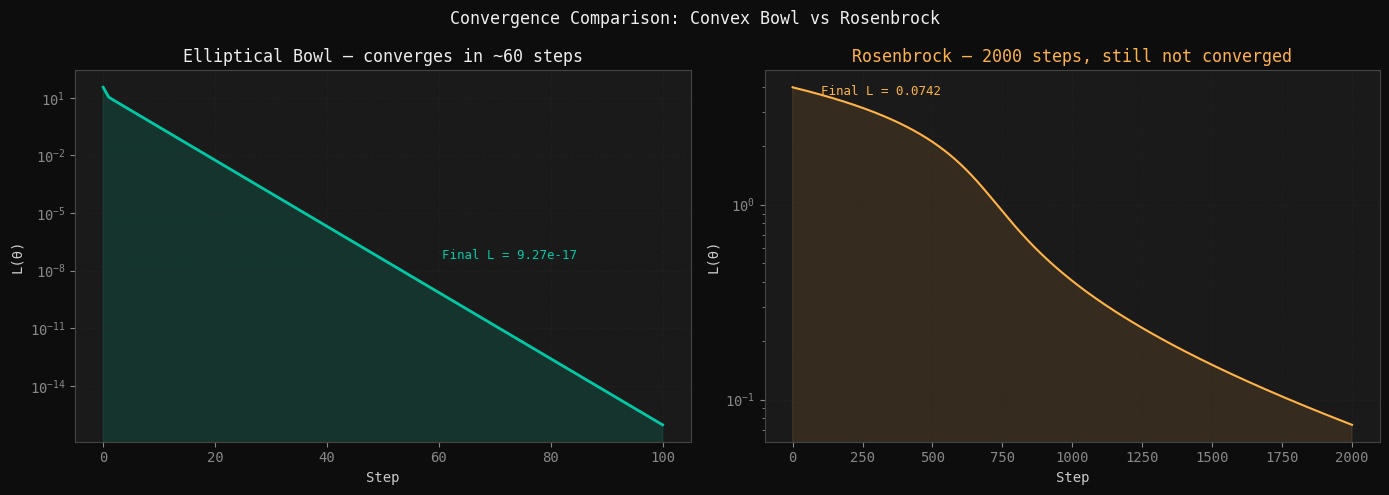

Bowl:        101 steps → L = 9.27e-17
Rosenbrock:  2000 steps → L = 0.0742  (minimum is L=0 at θ=(1,1))

The bowl converges in under 100 steps.
Rosenbrock barely moves after 2000. Same algorithm. Same learning rate logic.
The difference is entirely the geometry of the loss surface.


In [12]:
# Loss convergence comparison: bowl vs Rosenbrock

path_bowl, losses_bowl = gradient_descent_2d(
    loss_bowl, grad_bowl, np.array([4.0, 2.0]), lr=0.09, n_steps=100)

path_rb_best, losses_rb_best = gradient_descent_2d(
    loss_rosenbrock, grad_rosenbrock,
    np.array([-1.0, 1.0]), lr=0.001, n_steps=2000)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Convergence Comparison: Convex Bowl vs Rosenbrock",
             color=WHITE, fontsize=12)

# Bowl
ax1.plot(losses_bowl, color=TEAL, lw=2)
ax1.fill_between(range(len(losses_bowl)), losses_bowl, alpha=0.15, color=TEAL)
ax1.set_title("Elliptical Bowl — converges in ~60 steps", color=WHITE)
ax1.set_xlabel("Step"); ax1.set_ylabel("L(θ)")
ax1.grid(True, alpha=0.3)
ax1.set_yscale('log')

# Rosenbrock
ax2.plot(losses_rb_best, color=AMBER, lw=1.5)
ax2.fill_between(range(len(losses_rb_best)), losses_rb_best, alpha=0.12, color=AMBER)
ax2.set_title("Rosenbrock — 2000 steps, still not converged", color=AMBER)
ax2.set_xlabel("Step"); ax2.set_ylabel("L(θ)")
ax2.grid(True, alpha=0.3)
ax2.set_yscale('log')

# Annotate final values
ax1.text(len(losses_bowl)*0.6, losses_bowl[len(losses_bowl)//2],
         f"Final L = {losses_bowl[-1]:.2e}", color=TEAL, fontsize=9)
ax2.text(len(losses_rb_best)*0.05, losses_rb_best[100],
         f"Final L = {losses_rb_best[-1]:.4f}", color=AMBER, fontsize=9)

plt.tight_layout()
plt.savefig('convergence_comparison.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

print(f"Bowl:        {len(losses_bowl)} steps → L = {losses_bowl[-1]:.2e}")
print(f"Rosenbrock:  2000 steps → L = {losses_rb_best[-1]:.4f}  "
      f"(minimum is L=0 at θ=(1,1))")
print()
print("The bowl converges in under 100 steps.")
print("Rosenbrock barely moves after 2000. Same algorithm. Same learning rate logic.")
print("The difference is entirely the geometry of the loss surface.")

---
## Section 7 — What This Tells Us About Optimisers

Vanilla gradient descent has one mechanism: move opposite to the gradient, scaled by $\eta$.

The Rosenbrock surface reveals two structural problems with this:

### Problem 1 — The valley floor
Along the floor of the Rosenbrock valley, the gradient is tiny.  
The update $\theta_{t+1} = \theta_t - \eta \nabla L$ is nearly zero every step.  
GD crawls because it has no memory of where it has been going.

**What momentum adds:** accumulate velocity across steps — keep moving  
in a direction even when the gradient is small, like a ball rolling downhill.

### Problem 2 — Curvature is not uniform
The Rosenbrock is steep across the valley and flat along it.  
A single learning rate cannot handle both directions simultaneously:  
large enough to move along the floor = too large for the walls.

**What Adam adds:** a per-parameter adaptive learning rate — effectively  
dividing by the magnitude of recent gradients, making steps smaller  
where gradients are large and larger where they are small.

### The point

Vanilla GD is not broken. It is the foundation.  
Momentum and Adam are not alternatives to it — they are extensions  
that add memory and adaptivity to the same core update rule.

$$\theta_{t+1} = \theta_t - \eta \nabla L(\theta_t) \quad \text{(the rule everything else extends)}$$

Understanding this equation from first principles — which you now do —  
is what makes every other optimiser readable rather than magical.

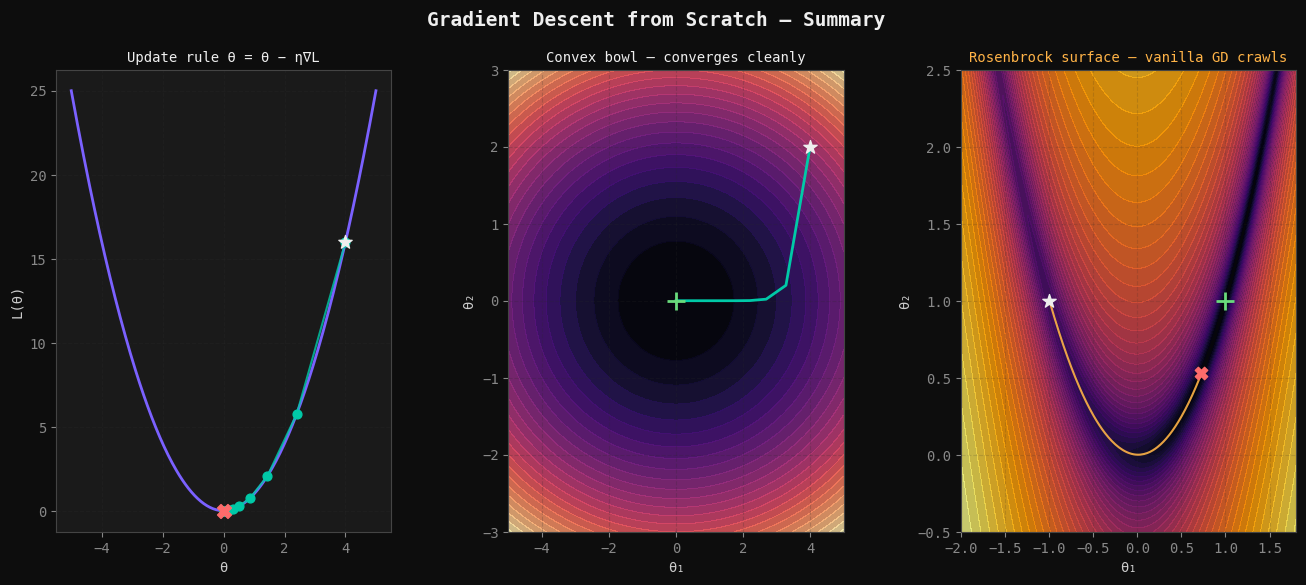

Three panels. One algorithm. Two very different surfaces.

The update rule is the same in all three:
  θ = θ − η∇L

What changes is the geometry of L.
That geometry determines everything: speed, stability, where you land.

Next episode: the loss landscape — what that geometry looks like,
why flat minima generalise better, and the mathematics of curvature.


In [13]:
# Final summary plot — the full picture

fig = plt.figure(figsize=(16, 6))
fig.patch.set_facecolor('#0d0d0d')
fig.suptitle("Gradient Descent from Scratch — Summary",
             color=WHITE, fontsize=14, fontweight='bold')

gs = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)

# Panel 1: Update rule visualised in 1D
ax1 = fig.add_subplot(gs[0])
theta_range_1d = np.linspace(-5, 5, 300)
ax1.plot(theta_range_1d, loss_1d(theta_range_1d), color=PURPLE, lw=2)
history_summary = gradient_descent_1d(theta_init=4.0, lr=0.2, n_steps=15)
ax1.scatter(history_summary, loss_1d(history_summary), color=TEAL, s=40, zorder=5)
ax1.plot(history_summary, loss_1d(history_summary), color=TEAL, lw=1.5, alpha=0.8)
ax1.scatter([history_summary[0]], [loss_1d(history_summary[0])],
            color=WHITE, s=100, marker='*', zorder=6)
ax1.scatter([history_summary[-1]], [loss_1d(history_summary[-1])],
            color=CORAL, s=100, marker='X', zorder=6)
ax1.set_title("Update rule θ = θ − η∇L", color=WHITE, fontsize=10)
ax1.set_xlabel("θ"); ax1.set_ylabel("L(θ)")
ax1.grid(True, alpha=0.3)

# Panel 2: Bowl contour
ax2 = fig.add_subplot(gs[1])
path_s, _ = gradient_descent_2d(loss_bowl, grad_bowl,
                                  np.array([4.0, 2.0]), 0.09, 60)
ax2.contourf(T1, T2, Z_bowl, levels=25, cmap='magma', alpha=0.8)
ax2.plot(path_s[:, 0], path_s[:, 1], color=TEAL, lw=2)
ax2.scatter(*np.array([4.0, 2.0]), color=WHITE, s=100, marker='*', zorder=5)
ax2.scatter(0, 0, color=GREEN, s=150, marker='+', zorder=5, linewidths=2)
ax2.set_title("Convex bowl — converges cleanly", color=WHITE, fontsize=10)
ax2.set_xlabel("θ₁"); ax2.set_ylabel("θ₂")
ax2.grid(True, alpha=0.2)

# Panel 3: Rosenbrock contour
ax3 = fig.add_subplot(gs[2])
path_r, _ = gradient_descent_2d(loss_rosenbrock, grad_rosenbrock,
                                  np.array([-1.0, 1.0]), 0.001, 2000)
p_clip = np.clip(path_r, -2.0, 1.8)
stride = max(1, len(p_clip) // 200)
ax3.contourf(T1_rb, T2_rb, np.log1p(Z_rb), levels=40, cmap='inferno', alpha=0.8)
ax3.plot(p_clip[::stride, 0], p_clip[::stride, 1], color=AMBER, lw=1.5, alpha=0.9)
ax3.scatter(p_clip[0, 0], p_clip[0, 1], color=WHITE, s=100, marker='*', zorder=5)
ax3.scatter(1, 1, color=GREEN, s=150, marker='+', zorder=5, linewidths=2)
ax3.scatter(p_clip[-1, 0], p_clip[-1, 1], color=CORAL, s=80, marker='X', zorder=5)
ax3.set_xlim(-2.0, 1.8); ax3.set_ylim(-0.5, 2.5)
ax3.set_title("Rosenbrock surface — vanilla GD crawls", color=AMBER, fontsize=10)
ax3.set_xlabel("θ₁"); ax3.set_ylabel("θ₂")
ax3.grid(True, alpha=0.15)

plt.savefig('gd_summary.png', dpi=150, bbox_inches='tight',
            facecolor='#0d0d0d', edgecolor='none')
plt.show()

print("Three panels. One algorithm. Two very different surfaces.")
print()
print("The update rule is the same in all three:")
print("  θ = θ − η∇L")
print()
print("What changes is the geometry of L.")
print("That geometry determines everything: speed, stability, where you land.")
print()
print("Next episode: the loss landscape — what that geometry looks like,")
print("why flat minima generalise better, and the mathematics of curvature.")

---

## Summary

| Concept | Key result |
|---|---|
| Update rule | $\theta_{t+1} = \theta_t - \eta \nabla L(\theta_t)$ — subtract scaled gradient |
| Learning rate | Controls step size — too small crawls, too large diverges |
| Convex surface | GD guaranteed to find global minimum — converges cleanly |
| Rosenbrock | Non-convex, curved valley — GD finds the valley then crawls |
| Failure mode | Flat gradient along valley floor — no memory of direction |
| What's next | Momentum and Adam extend this rule — they do not replace it |

---

*Decoding Complexities · pradeeppanga.com · @DecodingComplexities*